# NB03 — PV forecast model

**SOLA4237 Assignment 2 — single-site battery optimisation, Toowoomba (QLD)**

**Purpose.** Build a data-driven PV model on **2022** (measured PV) and use **2023 weather** to forecast 2023 PV.
Compare it with the commercial forecast (treated as the actual 2023 PV) using MAE, RMSE and nRMSE, and add P10/P90 uncertainty bands.
The best point forecast is the PV input for the rolling-horizon runs in subsequent notebook 7 (run R2 and R4).

**Models**
- **M1 physics-based** (Topic 4 slide 8): P = k · G/1000 · [1 + β (T_cell − 25)], with T_cell = T_amb + (NOCT − 20)/800 · G,
  β = −0.004 /°C (metadata), NOCT = 45 °C; one scale factor k (≈ kWp × PR) fitted by least squares.
- **M2 data-driven ML** (Workshop week 9): DecisionTreeRegressor on irradiance, temperature, time of day and month.
- **Benchmark** (Topic 4 slide 33): seasonal naive — PV at the same time the day before. A model that cannot beat it is not worth using.

**Uncertainty:** empirical prediction intervals — P10/P90 = point forecast + 10th/90th percentile of the 2022 residuals in the same irradiance bin;
evaluated with coverage, range (Topic 4 slide 38) and Mean Interval Score (Topic 9 p.32).

**Input:** `outputs/nb01_clean_2022_2023.csv`. **Outputs:** `outputs/nb03_pv_forecast_2023_5min.csv`, `outputs/nb03_pv_forecast_2023_hourly.csv`,
`outputs/nb03_pv_errors.csv`, figures fig07a–fig07b.

**Caveat:** the "forecast" uses *measured* 2023 weather (brief instruction), so its error is model error only — no weather-forecast
error. Real-world PV forecast errors might be larger.

## Cell 0 — Settings

In [1]:
# Cell 0 - Settings: runs in Google Colab and in local Jupyter
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/SOLA4237-A2'
else:
    BASE_DIR = os.getcwd()                    # local: the data folder or its 'Notebook' subfolder
    if not os.path.exists(os.path.join(BASE_DIR, 'QLD_spot_price_2023')):
        BASE_DIR = os.path.dirname(BASE_DIR)
sys.path.append(BASE_DIR)
OUT_DIR = os.path.join(BASE_DIR, 'outputs')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
print('BASE_DIR:', BASE_DIR)

Mounted at /content/drive
BASE_DIR: /content/drive/MyDrive/SOLA4237-A2


## Cell 1 — Imports, constants and data

In [2]:
# Cell 1 - imports, constants, data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

DT_H = 5 / 60
BETA = -0.004          # PV temperature coefficient (1/°C), metadata
NOCT = 45.0            # nominal operating cell temperature (°C), typical datasheet [R33]
T_REF = 25.0           # STC reference temperature (°C)
SEED = 42              # reproducible tree
COL = {'actual': '#000000', 'm1': '#1f77b4', 'm2': '#2ca02c', 'naive': '#9467bd', 'band': '#1f77b4'}
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

df = pd.read_csv(os.path.join(OUT_DIR, 'nb01_clean_2022_2023.csv'), parse_dates=['datetime'])
df['hour_frac'] = df['datetime'].dt.hour + df['datetime'].dt.minute / 60
df['month'] = df['datetime'].dt.month
print(df.shape)

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches='tight')

(210240, 28)


## Cell 2 — Train/test split by date (Week 9 `split_train_test_by_date` idea)
**Train** = 2022 (target: measured PV). **Test** = 2023 (target: commercial PV = actual).
Models are fitted on **daylight** rows only (irradiance > 0); at night every forecast is set to 0.

In [3]:
# Cell 2 - split by date
train = df[(df.year == 2022) & (df.irradiance_wm2 > 0)].copy()
test_all = df[df.year == 2023].copy()                         # all 2023 rows (night included)
y_train = train['pv_measured_kw']
PV_MAX = float(df.loc[df.year == 2022, 'pv_measured_kw'].max())   # physical upper bound for clipping
print('train rows (2022 daylight):', len(train), '| test rows (2023, all):', len(test_all), '| PV_MAX = %.2f kW' % PV_MAX)

train rows (2022 daylight): 58970 | test rows (2023, all): 105120 | PV_MAX = 14.55 kW


## Cell 3 — M1 physics-based model (Topic 4 slide 8)
**How:** compute the physics feature x = G/1000 · [1 + β (T_cell − 25)] and fit PV = k · x (no intercept). k ≈ kWp × PR

In [4]:
# Cell 3 - M1 physics model
def physics_feature(d):
    # x = G/1000 * (1 + beta * (T_cell - 25)), with T_cell from the NOCT model
    t_cell = d['temperature_c'] + (NOCT - 20.0) / 800.0 * d['irradiance_wm2']
    return (d['irradiance_wm2'] / 1000.0) * (1.0 + BETA * (t_cell - T_REF))

m1 = LinearRegression(fit_intercept=False)
m1.fit(physics_feature(train).to_frame('x'), y_train)
k = m1.coef_[0]
print('fitted k = %.2f kW per (kW/m2)  -> implied size %.1f kWp at PR 0.85' % (k, k / 0.85))

def predict_m1(d):
    p = m1.predict(physics_feature(d).to_frame('x'))
    p = np.where(d['irradiance_wm2'] > 0, p, 0.0)
    return np.clip(p, 0, PV_MAX)

fitted k = 11.39 kW per (kW/m2)  -> implied size 13.4 kWp at PR 0.85


## Cell 4 — M2 data-driven model: decision tree (Week 9)
**How:** DecisionTreeRegressor with irradiance, temperature, time of day (decimal hours) and month. `max_depth=8` and
`min_samples_leaf=50` keep it from memorising single intervals; `random_state` makes it reproducible.

In [5]:
# Cell 4 - M2 decision tree
FEATURES = ['irradiance_wm2', 'temperature_c', 'hour_frac', 'month']
m2 = DecisionTreeRegressor(max_depth=8, min_samples_leaf=50, random_state=SEED)
m2.fit(train[FEATURES], y_train)
print('feature importance:', dict(zip(FEATURES, m2.feature_importances_.round(3))))

def predict_m2(d):
    p = m2.predict(d[FEATURES])
    p = np.where(d['irradiance_wm2'] > 0, p, 0.0)
    return np.clip(p, 0, PV_MAX)

feature importance: {'irradiance_wm2': np.float64(0.998), 'temperature_c': np.float64(0.001), 'hour_frac': np.float64(0.0), 'month': np.float64(0.0)}


## Cell 5 — Forecasts for 2023 and the seasonal-naive benchmark
**Benchmark:** PV at time t = actual PV at t − 24 h (known history at forecast time). This is the day-ahead version; a 48 h plan would use
t − 24 h for the first day and t − 48 h for the second.

In [6]:
# Cell 5 - 2023 forecasts
test_all['pv_m1_kw'] = predict_m1(test_all)
test_all['pv_m2_kw'] = predict_m2(test_all)
full_actual = df.set_index('datetime')['pv_actual_kw']
test_all['pv_naive_kw'] = full_actual.shift(288).reindex(test_all['datetime']).values   # same time yesterday
train['pv_m1_kw'] = predict_m1(train)
train['pv_m2_kw'] = predict_m2(train)
print(test_all[['pv_actual_kw', 'pv_m1_kw', 'pv_m2_kw', 'pv_naive_kw']].describe().round(2))

       pv_actual_kw   pv_m1_kw   pv_m2_kw  pv_naive_kw
count     105120.00  105120.00  105120.00    105120.00
mean           2.43       2.38       2.36         2.43
std            3.21       3.09       3.13         3.21
min            0.00       0.00       0.00         0.00
25%            0.00       0.00       0.00         0.00
50%            0.23       0.24       0.24         0.23
75%            4.83       4.85       4.73         4.82
max           11.58      10.66      11.49        11.90


## Cell 6 — Point-forecast errors vs the commercial forecast
**Metrics** (Topic 4 slide 37, Week 8 Task 7):
- MAE = mean |forecast − actual|; RMSE = √mean (forecast − actual)²; **nRMSE = RMSE / mean daylight actual PV** (normaliser stated);
  bias = mean (forecast − actual); annual energy difference in %.
- Computed on **daylight** intervals (irradiance > 0 or actual PV > 0); night errors are zero by construction and would flatter the scores.
- 2022 scores are in-sample (training) — shown only to check for over-fitting.

In [7]:
# Cell 6 - error table
def calc_errors(actual, forecast, daylight):
    # MAE, RMSE, nRMSE (RMSE / mean daylight actual), bias (kW) and annual energy difference (%)
    a, f = actual[daylight], forecast[daylight]
    e = f - a
    rmse = np.sqrt((e ** 2).mean())
    return {'MAE_kW': e.abs().mean(), 'RMSE_kW': rmse, 'nRMSE_%': 100 * rmse / a.mean(), 'bias_kW': e.mean(),
            'energy_diff_%': 100 * (forecast.sum() - actual.sum()) / actual.sum()}

day23 = (test_all.irradiance_wm2 > 0) | (test_all.pv_actual_kw > 0)
rows = {}
for name, col in [('M1 physics', 'pv_m1_kw'), ('M2 decision tree', 'pv_m2_kw'), ('Seasonal naive', 'pv_naive_kw')]:
    rows[(name, '2023 test')] = calc_errors(test_all.pv_actual_kw, test_all[col], day23)
for name, col in [('M1 physics', 'pv_m1_kw'), ('M2 decision tree', 'pv_m2_kw')]:
    rows[(name, '2022 train')] = calc_errors(train.pv_measured_kw, train[col], train.index == train.index)
errors = pd.DataFrame(rows).T
print(errors.round(3))

best_name = errors.xs('2023 test', level=1)['nRMSE_%'].drop('Seasonal naive').idxmin()
best_col = {'M1 physics': 'pv_m1_kw', 'M2 decision tree': 'pv_m2_kw'}[best_name]
print('\nBest model on 2023 (lowest nRMSE):', best_name)
assert errors.loc[(best_name, '2023 test'), 'nRMSE_%'] < errors.loc[('Seasonal naive', '2023 test'), 'nRMSE_%'], 'model does not beat the benchmark'

                             MAE_kW  RMSE_kW  nRMSE_%  bias_kW  energy_diff_%
M1 physics       2023 test    0.136    0.226    5.233   -0.084         -1.950
M2 decision tree 2023 test    0.131    0.207    4.786   -0.113         -2.628
Seasonal naive   2023 test    0.878    1.526   35.355   -0.000         -0.008
M1 physics       2022 train   0.424    0.797   20.518    0.047          1.200
M2 decision tree 2022 train   0.414    0.777   20.003    0.000          0.000

Best model on 2023 (lowest nRMSE): M2 decision tree


## Cell 7 — Visual check: a clear week, a cloudy week, and forecast vs actual
Weeks are picked automatically: the 2023 week with the highest and the lowest actual PV energy.

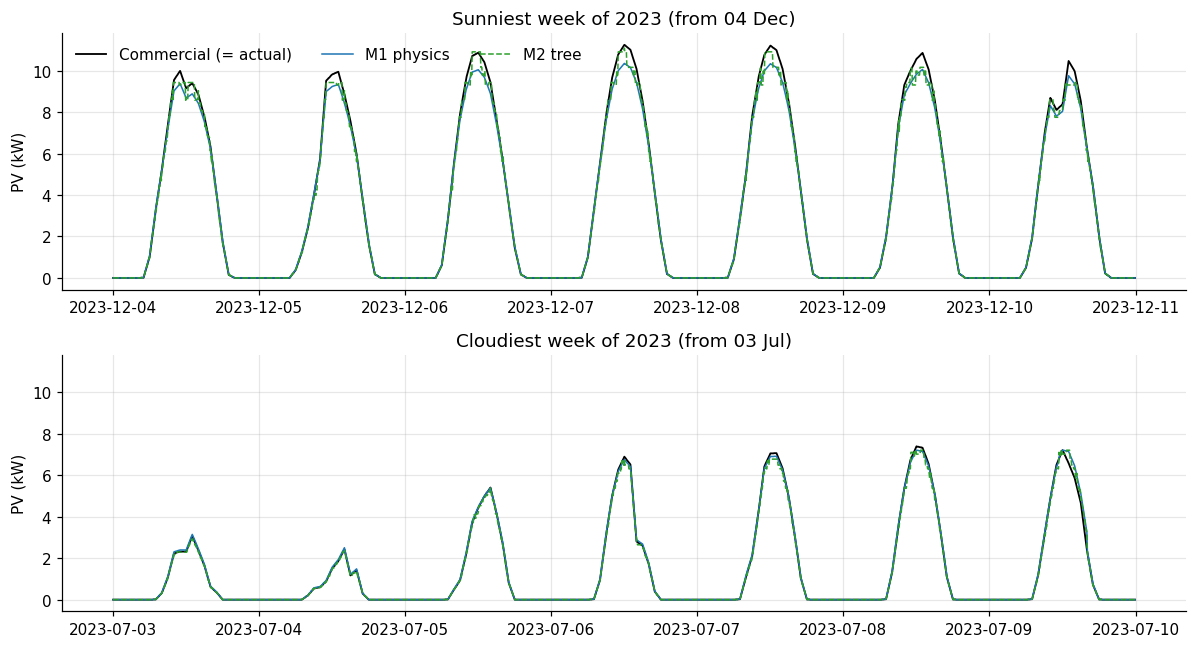

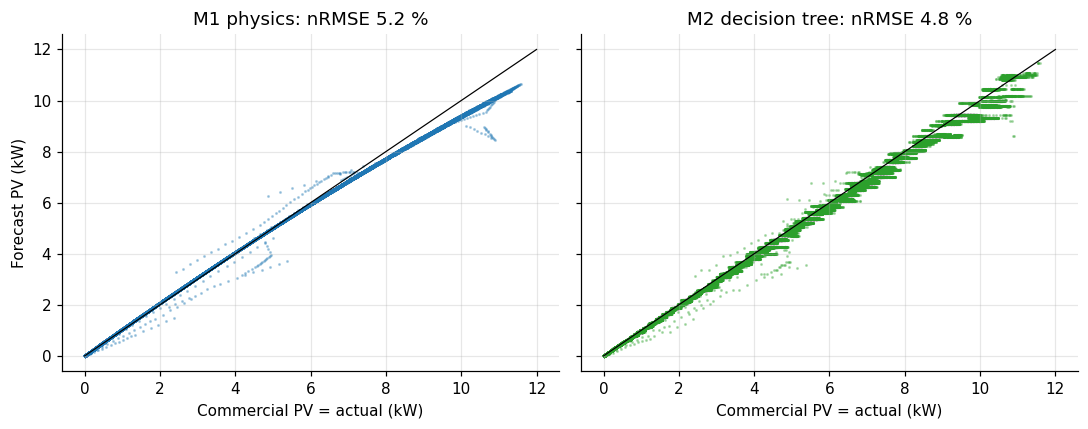

In [8]:
# Cell 7 - plots
weekly = test_all.set_index('datetime')['pv_actual_kw'].resample('W-MON', label='left', closed='left').sum()
weekly = weekly.iloc[1:-1]                                     # drop partial first/last weeks
weeks = {'Sunniest week': weekly.idxmax(), 'Cloudiest week': weekly.idxmin()}

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharey=True)
for ax, (title, start) in zip(axes, weeks.items()):
    w = test_all[(test_all.datetime >= start) & (test_all.datetime < start + pd.Timedelta(days=7))]
    ax.plot(w.datetime, w.pv_actual_kw, color=COL['actual'], lw=1.2, label='Commercial (= actual)')
    ax.plot(w.datetime, w.pv_m1_kw, color=COL['m1'], lw=1, label='M1 physics')
    ax.plot(w.datetime, w.pv_m2_kw, color=COL['m2'], lw=1, ls='--', label='M2 tree')
    ax.set_title(f'{title} of 2023 (from {start:%d %b})'); ax.set_ylabel('PV (kW)')
axes[0].legend(ncol=3, frameon=False)
plt.tight_layout(); save_fig(fig, 'fig07a_pv_forecast_weeks_2023.png'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, col) in zip(axes, [('M1 physics', 'pv_m1_kw'), ('M2 decision tree', 'pv_m2_kw')]):
    d = test_all[day23]
    ax.scatter(d.pv_actual_kw, d[col], s=1, alpha=0.3, color=COL['m1' if col == 'pv_m1_kw' else 'm2'])
    ax.plot([0, 12], [0, 12], 'k', lw=0.8)
    ax.set_title(f"{name}: nRMSE {errors.loc[(name, '2023 test'), 'nRMSE_%']:.1f} %")
    ax.set_xlabel('Commercial PV = actual (kW)')
axes[0].set_ylabel('Forecast PV (kW)')
plt.tight_layout(); plt.show()

## Cell 8 — Uncertainty: empirical P10/P90 bands
**How:** on 2022, residual = actual − forecast of the best model. Group residuals into irradiance bins (deciles of daylight irradiance)
and take the 10th and 90th percentile per bin. For 2023: P10 = forecast + q10(bin), P90 = forecast + q90(bin), clipped to [0, PV_MAX].
**Evaluation (nominal 80 % interval, α = 0.2):**
- Coverage = share of actual values inside [P10, P90] (target ≈ 80 %); Range = mean (P90 − P10).
- Mean Interval Score = mean[(U − L) + (2/α)(L − y)·1(y < L) + (2/α)(y − U)·1(y > U)] — lower is better (Topic 9 p.32).

                  q10   q90
g_bin                      
(-0.001, 15.0]  -0.01  0.01
(15.0, 62.0]    -0.05  0.06
(62.0, 134.7]   -0.15  0.17
(134.7, 229.0]  -0.27  0.30
(229.0, 331.0]  -0.42  0.46
(331.0, 438.0]  -0.58  0.65
(438.0, 541.0]  -0.72  0.82
(541.0, 642.0]  -0.89  1.02
(642.0, 780.0]  -1.01  1.12
(780.0, 1142.0] -1.30  1.47

P10-P90 on 2023 daylight:
coverage_%       99.321
mean_range_kW     1.245
MIS_kW            1.251
dtype: float64


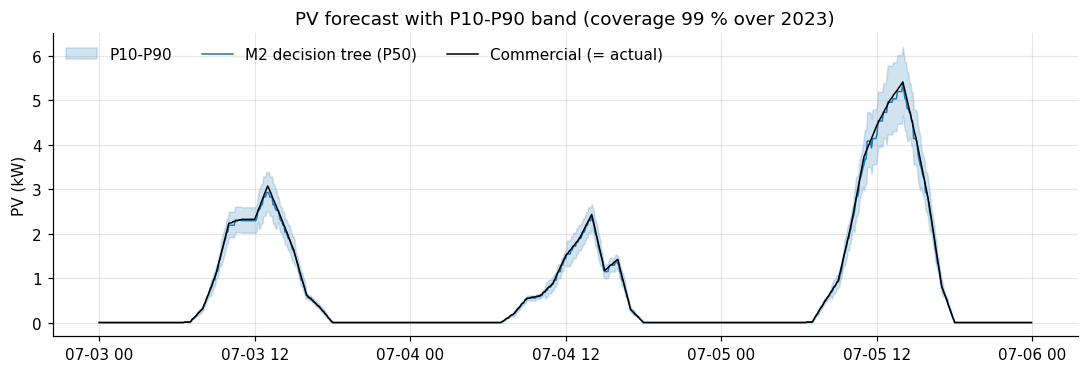

In [9]:
# Cell 8 - empirical prediction intervals
ALPHA = 0.2
train['resid'] = train['pv_measured_kw'] - train[best_col]
edges = np.unique(np.quantile(train['irradiance_wm2'], np.linspace(0, 1, 11)))
edges[0], edges[-1] = 0.0, max(edges[-1], test_all['irradiance_wm2'].max()) + 1
train['g_bin'] = pd.cut(train['irradiance_wm2'], edges, include_lowest=True)
q = train.groupby('g_bin', observed=False)['resid'].quantile([0.1, 0.9]).unstack()
q.columns = ['q10', 'q90']
print(q.round(2))

test_all['g_bin'] = pd.cut(test_all['irradiance_wm2'], edges, include_lowest=True)
qq = test_all['g_bin'].map(q['q10']).astype(float).fillna(0), test_all['g_bin'].map(q['q90']).astype(float).fillna(0)
night = test_all['irradiance_wm2'] <= 0
test_all['pv_p10_kw'] = np.where(night, 0, np.clip(test_all[best_col] + qq[0], 0, PV_MAX))
test_all['pv_p90_kw'] = np.where(night, 0, np.clip(test_all[best_col] + qq[1], 0, PV_MAX))

y, L, U = test_all.loc[day23, 'pv_actual_kw'], test_all.loc[day23, 'pv_p10_kw'], test_all.loc[day23, 'pv_p90_kw']
coverage = ((y >= L) & (y <= U)).mean()
width = (U - L).mean()
mis = ((U - L) + (2 / ALPHA) * (L - y) * (y < L) + (2 / ALPHA) * (y - U) * (y > U)).mean()
interval_scores = pd.Series({'coverage_%': 100 * coverage, 'mean_range_kW': width, 'MIS_kW': mis})
print('\nP10-P90 on 2023 daylight:'); print(interval_scores.round(3))

w = test_all[(test_all.datetime >= weeks['Cloudiest week']) & (test_all.datetime < weeks['Cloudiest week'] + pd.Timedelta(days=3))]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.fill_between(w.datetime, w.pv_p10_kw, w.pv_p90_kw, color=COL['band'], alpha=0.2, label='P10-P90')
ax.plot(w.datetime, w[best_col], color=COL['band'], lw=1, label=f'{best_name} (P50)')
ax.plot(w.datetime, w.pv_actual_kw, color=COL['actual'], lw=1, label='Commercial (= actual)')
ax.set_ylabel('PV (kW)'); ax.set_title(f'PV forecast with P10-P90 band (coverage {100*coverage:.0f} % over 2023)')
ax.legend(ncol=3, frameon=False); plt.tight_layout(); save_fig(fig, 'fig07b_pv_forecast_band.png'); plt.show()

## Cell 9 — Save the forecast for notebook 7
- 5-min file: point forecast (best model), P10, P90 and the commercial actual for 2023.
- Hourly file: means over each hour, **interval-ending labels** (`label='right', closed='right'`)

In [10]:
# Cell 9 - save outputs
out5 = test_all[['datetime', 'pv_actual_kw', 'pv_m1_kw', 'pv_m2_kw', 'pv_p10_kw', 'pv_p90_kw']].copy()
out5.insert(2, 'pv_forecast_kw', test_all[best_col].values)    # best model = the forecast used in NB07
out5.to_csv(os.path.join(OUT_DIR, 'nb03_pv_forecast_2023_5min.csv'), index=False)

hourly = out5.set_index('datetime')[['pv_actual_kw', 'pv_forecast_kw', 'pv_p10_kw', 'pv_p90_kw']] \
             .resample('h', label='right', closed='right').mean()
hourly.to_csv(os.path.join(OUT_DIR, 'nb03_pv_forecast_2023_hourly.csv'))
errors.to_csv(os.path.join(OUT_DIR, 'nb03_pv_errors.csv'))
interval_scores.to_frame('value').to_csv(os.path.join(OUT_DIR, 'nb03_pv_interval_scores.csv'))
print('best model used:', best_name, '| 5-min rows:', len(out5), '| hourly rows:', len(hourly))
print('annual energy 2023: actual %.0f kWh, forecast %.0f kWh' % (out5.pv_actual_kw.sum() * DT_H, out5.pv_forecast_kw.sum() * DT_H))

best model used: M2 decision tree | 5-min rows: 105120 | hourly rows: 8761
annual energy 2023: actual 21248 kWh, forecast 20689 kWh




## AI-use record (Appendix A)
| Item | Entry |
|---|---|
| Tool & model | Claude Opus 5.5 (Anthropic), claude.ai, 21 Nov 2026 |
| What AI did | Drafted this notebook from my notes (Topic 4 PV model; workshop Week 9 tree) |
| Example prompt | “notebook 2 done. now draft the notebook 3” |
| How I checked it | ran it in Colab; recomputed MAE for one day by hand; checked that night forecasts are 0; looked at the week plots |